# Stochastic Simulation and Parameter Inference of an SIR Model on Sparse Networks

The SIR model is a foundational framework for understanding contagion dynamics. Classically, this model is implemented using Ordinary Differential Equations (ODEs), which assume a well-mixed population: every individual interacts with every other with equal probability (the mean-field approximation). 

To model realistic dynamics, we transition to a discrete stochastic implementation via **sparse graphs**. Here, nodes represent individuals and edges represent specific contact pathways. Unlike dense matrices, a sparse graph reflects the empirical fact that an individual has a limited number of contacts relative to the total population size.

To simulate the time evolution of our system, we employ the exact **Gillespie algorithm (Stochastic Simulation Algorithm)**, which treats the epidemic as a continuous-time Markov Process where:
- The time to the next event is drawn from an exponential distribution.
- The event (infection or recovery) is selected probabilistically, proportional to its individual rate.

We assume uniform infection ($\lambda$) and recovery ($\mu$) rates across all individuals.

In [1]:
using Pkg
Pkg.activate("..")

# Import our custom physics and inference engine
include("../src/StochasticMethods.jl")
using .StochasticMethods

using SparseArrays
using LinearAlgebra
using Plots

  Activating project at `c:\Users\lucar\OneDrive\Desktop\varie\github projects\stochastic-methods`


## 1. Simulating the Ground Truth Epidemic

First, we establish our environment and simulate an unobserved "ground truth" trajectory. We generate a population of $N=1000$ individuals connected via a random sparse network with an average degree of 10 (meaning each person has 10 contacts on average). 

We set our hidden true parameters to $\lambda = 0.4$ and $\mu = 0.2$. The simulation runs in continuous time, but we record the cumulative state of the system at evenly spaced discrete time steps using our custom `DeltaRecorder`.

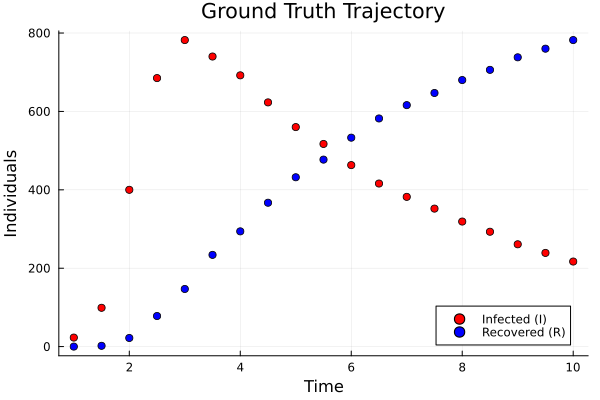

In [2]:
# --- Network and Simulation Parameters ---
N = 1000
avg_degree = 10
λ_real = 0.4 
μ_real = 0.2 
T = 10

# Generate a sparse adjacency matrix with no self-loops
G = generate_sparse_graph(N, avg_degree)

# --- Simulate Ground Truth ---
vT = 1:(T/20):T
x = fill(0, N) 
stats = DeltaRecorder(vT)

# Run the Gillespie SSA
obs_I, obs_R = sample!(x, G, λ_real, μ_real, T; stats=stats)

# Reconstruct absolute population numbers via cumulative sum
Ostar = (cumsum(obs_I), cumsum(obs_R))

# Visualize the Trajectory
p1 = scatter(vT, Ostar[1], label="Infected (I)", color=:red, xlabel="Time", ylabel="Individuals", title="Ground Truth Trajectory")
scatter!(p1, vT, Ostar[2], label="Recovered (R)", color=:blue)
display(p1)

## 2. Parameter Inference via Maximum Log-Likelihood

Let us assume the ground truth trajectory $X^*$ has been sampled, but we only have access to the discrete observation array $O^*$. Our goal is to deduce the underlying parameters $\lambda$ and $\mu$.

Using Bayes' theorem with a uniform prior, we seek to maximize the likelihood:
$$
\lambda^\star,\mu^\star = \arg\max_{\lambda,\mu}\mathbb{P}(O^*|\lambda,\mu)
$$

For a given parameter pair $(\lambda,\mu)$, the likelihood is the expectation value $\left<\delta_{O^*,O(X)}\right>_{p(X|\lambda,\mu)}$. We approximate this by drawing $M$ different Monte Carlo samples $X_1,\dots,X_M \sim p(X|\lambda,\mu)$ from the process.

### The Soft Approximation
For moderately large systems, requiring exact state matches via a Kronecker delta ($\delta$) leads to extreme sparsity—we would need a computationally unfeasible number of samples to find even one exact match for the observed time-series. 

Instead, we approximate the delta with a continuous, distance-based "soft" weight:
$$
\mathbb{P}(O^*|\lambda,\mu)\approx\frac1M\sum_{m=1}^M e^{-\beta ||O^*-O(X_m)||}
$$
where $||\cdot||$ is the Euclidean norm. Note that $\lim_{\beta\to\infty} e^{-\beta ||O^*-O(X_m)||} = \delta_{O^*,O(X_m)}$. 

This allows us to handle slight simulation deviations continuously. To prevent numerical underflow over long trajectories, the computational implementation calculates the **Log-Likelihood**.

In [3]:
# --- Inference Parameters ---
# To ensure statistical stability of the expected likelihood and avoid fluctuating 
# argmax results, we use a robust number of Monte Carlo samples (M = 1000) 
# instead of averaging the outputs of multiple noisy grid searches.

M = 1000  
β = 1.0   

# Define the grid search space
λ_range = 0.1:0.1:1.1
μ_range = 0.1:0.1:1.1

println("Running Log-Likelihood Inference over grid (this may take a minute)...")
Llog = maxloglikelihood(λ_range, μ_range, G, T, M, Ostar, β)

# Extract optimal parameters
max_idx = argmax(Llog)
λ_star = λ_range[max_idx[1]]
μ_star = μ_range[max_idx[2]]

println("\n--- Inference Results ---")
println("Ground truth: λ = $λ_real, μ = $μ_real")
println("Estimated:    λ* = $λ_star, μ* = $μ_star")

Running Log-Likelihood Inference over grid (this may take a minute)...

--- Inference Results ---
Ground truth: λ = 0.4, μ = 0.2
Estimated:    λ* = 0.4, μ* = 0.2


## 3. Visualizing the Inference Landscape

Finally, we plot the Log-Likelihood landscape. The convergence of the thermal peak demonstrates the capability of the stochastic model to back-propagate through the noisy, discrete observations to find the true continuous transmission parameters.

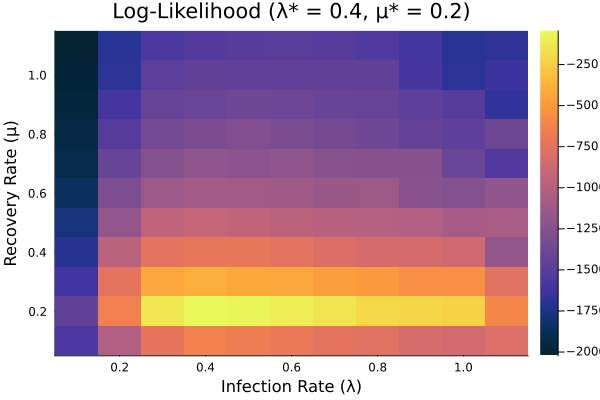

In [4]:
p2 = heatmap(
    λ_range, μ_range, Llog', # Transposed for correct spatial alignment (X, Y)
    title="Log-Likelihood (λ* = $λ_star, μ* = $μ_star)",
    xlabel="Infection Rate (λ)",
    ylabel="Recovery Rate (μ)",
    seriescolor=:thermal
)
display(p2)